# ✈️ Malaga Airport Analytics: January-September 2026

**Flight Routes Analysis: January-September 2026**

This notebook explores flight routes, origins, destinations, and monthly flight activity at Málaga-Costa del Sol Airport using real aviation data.

### Objectives

- Analyze flight activity across the available months of 2026.
- Identify the most frequent destinations and origins.
- Explore the countries connected to Málaga.
- Compare flight activity between months.

### Datasets

- **Flight List:** OpenSky flight records from January 2026 to September 2026.
- **Airport Codes:** Airport names, countries, and ICAO identifiers.

**Tools:** Python, Pandas, Matplotlib and Jupyter Notebook

## 1. Data Loading
In this section, we load and combine flight records from January to September 2026, focusing on flights arriving at or departing from Málaga Airport (LEMG).

In [20]:
# ==========================================
# 1. LOAD DATASETS
# ==========================================

import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Find monthly files
files = sorted(Path("../data/flight_lists").glob("flight_list_2026*.parquet"))

print("Files found:", len(files))

# Store Malaga flights
malaga_data = []

for file in files:
    df = pd.read_parquet(file)

    # Filter Malaga flights
    df_malaga = df[(df["adep"] == "LEMG") | (df["ades"] == "LEMG")]

    malaga_data.append(df_malaga)

    print(file.name, ":", len(df_malaga), "records")

# Combine monthly DataFrames
df_2026 = pd.concat(malaga_data, ignore_index=True)

print("\nTotal Malaga records:", len(df_2026))

display(df_2026.head(3))

Files found: 9
flight_list_202601.parquet : 5803 records
flight_list_202602.parquet : 10416 records
flight_list_202603.parquet : 14221 records
flight_list_202604.parquet : 17331 records
flight_list_202605.parquet : 17915 records
flight_list_202606.parquet : 19329 records
flight_list_202607.parquet : 22065 records
flight_list_202608.parquet : 20163 records
flight_list_202609.parquet : 19395 records

Total Malaga records: 146638


,id,icao24,flt_id,dof,adep,ades,adep_p,ades_p,registration,model,typecode,icao_aircraft_class,icao_operator,first_seen,last_seen,version
0,-1586385021305471008,4ca9d0,RYR58PD,2026-01-01 00:00:00,EYKA,LEMG,,,EI-EVH,BOEING 737-8AS,B738,L2J,RYR,2026-01-01 04:13:45,2026-01-01 08:19:35,v0.0.2
1,786180149150185473,4ca625,RYR16LU,2026-01-01 00:00:00,LEMG,EGNT,,,EI-DWY,BOEING 737-8AS,B738,L2J,RYR,2026-01-01 04:51:00,2026-01-01 07:48:55,v0.0.2
2,-1779431256397137008,4d2500,RYR502N,2026-01-01 00:00:00,EKCH,LEMG,,,9H-VVN,Boeing 737 MAX 8-200,B38M,NaN,RYR,2026-01-01 04:56:35,2026-01-01 08:27:50,v0.0.2


## 2. Dataset Overview

After combining the monthly datasets, we explore the
structure and time coverage of the resulting DataFrame.

In [21]:
# ==========================================
# 2. DATASET OVERVIEW
# ==========================================

print("===== SHAPE =====")
print("Shape:", df_2026.shape)
print()
print("===== INFO =====")
print("Dataset information:")
df_2026.info()
print()
print("===== MISSING VALUES =====")
print("Missing values:")
display(df_2026.isna().sum())
print()
print("===== DUPLICATED RECORDS =====")
print("Duplicated records:")
print(df_2026.duplicated().sum())

===== SHAPE =====
Shape: (146638, 16)

===== INFO =====
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 146638 entries, 0 to 146637
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype
---  ------               --------------   -----
 0   id                   146638 non-null  int64
 1   icao24               146638 non-null  str  
 2   flt_id               146638 non-null  str  
 3   dof                  146638 non-null  str  
 4   adep                 132301 non-null  str  
 5   ades                 133181 non-null  str  
 6   adep_p               146638 non-null  str  
 7   ades_p               146638 non-null  str  
 8   registration         119458 non-null  str  
 9   model                80993 non-null   str  
 10  typecode             119245 non-null  str  
 11  icao_aircraft_class  99081 non-null   str  
 12  icao_operator        76819 non-null   str  
 13  first_seen           146638 non-null  str  
 14  last_seen            146638 non-nu

id                         0
icao24                     0
flt_id                     0
dof                        0
adep                   14337
ades                   13457
adep_p                     0
ades_p                     0
registration           27180
model                  65645
typecode               27393
icao_aircraft_class    47557
icao_operator          69819
first_seen                 0
last_seen                  0
version                    0
dtype: int64


===== DUPLICATED RECORDS =====
Duplicated records:
0


In [22]:
print("===== FLIGHTS BY MONTH =====")
# Convert dates
df_2026["dof"] = pd.to_datetime(df_2026["dof"],errors="coerce")

# Extract month
df_2026["month"] = df_2026["dof"].dt.month

# Count flights by month
flights_by_month = (df_2026.groupby("month").size().sort_index())

display(flights_by_month)

===== FLIGHTS BY MONTH =====


month
1     5803
2    10416
3    14221
4    17331
5    17915
6    19329
7    22065
8    20163
9    19395
dtype: int64

===== DATA VISUALIZATION =====


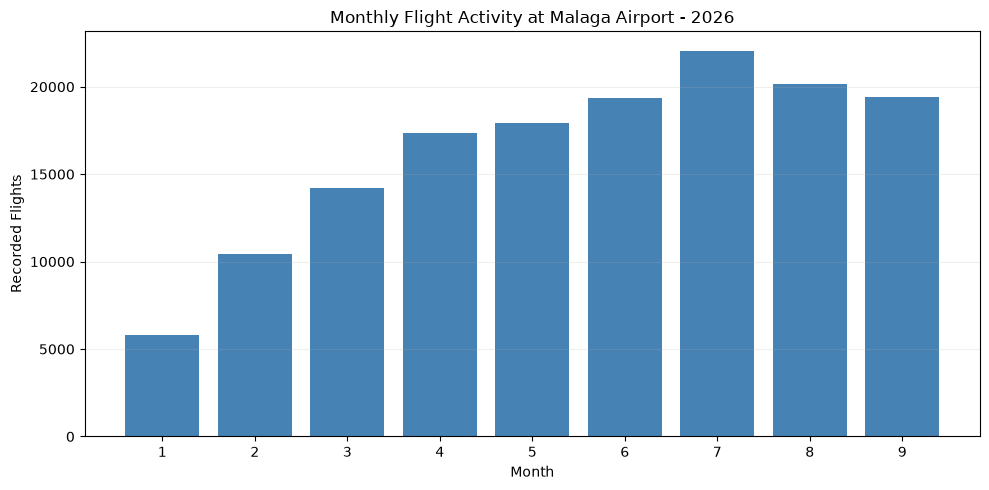

In [23]:
print("===== DATA VISUALIZATION =====")

plt.figure(figsize=(10, 5))

plt.bar(flights_by_month.index, flights_by_month.values, color="steelblue")

plt.title("Monthly Flight Activity at Malaga Airport - 2026")
plt.xlabel("Month")
plt.ylabel("Recorded Flights")

plt.xticks(range(1, 10))
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [24]:
print("===== DATE COVERAGE =====")
# Check date coverage
print("First date:", df_2026["dof"].min())
print("Last date:", df_2026["dof"].max())

# Records by year
display(df_2026["dof"].dt.year.value_counts())

===== DATE COVERAGE =====
First date: 2026-01-01 00:00:00
Last date: 2026-09-30 00:00:00


dof
2026    146638
Name: count, dtype: int64

## 3. Top 10 Destinations

This section identifies the most frequent flight destinations
from Málaga Airport during January–September 2026.

Airport names, cities and countries are added using Pandas merge().

In [25]:
# ==========================================
# 3. TOP DESTINATIONS FROM MALAGA
# ==========================================

# Load airport information
df_airports = pd.read_csv("../data/airport-codes.csv")

# Filter Malaga departures
df_departures = df_2026[df_2026["adep"] == "LEMG"].copy()

# Count flights by destination
top_destinations = (
    df_departures["ades"]
    .value_counts()
    .head(10)
    .reset_index()
)

# Add airport information
top_destinations = pd.merge(
    top_destinations,
    df_airports[["ident", "name", "municipality", "iso_country"]],
    left_on="ades",
    right_on="ident",
    how="left",
    validate="many_to_one"
)

# Simplify city names
top_destinations["municipality"] = (
    top_destinations["municipality"]
    .str.split(",")
    .str[0]
    .str.strip()
)

display(top_destinations)

,ades,count,ident,name,municipality,iso_country
0,EGKK,2727,EGKK,London Gatwick Airport,London,GB
1,LEMD,2216,LEMD,Adolfo Suárez Madrid–Barajas Airport,Madrid,ES
2,LEBL,2173,LEBL,Josep Tarradellas Barcelona-El Prat Airport,Barcelona,ES
3,EHAM,2025,EHAM,Amsterdam Airport Schiphol,Amsterdam,NL
4,EIDW,1679,EIDW,Dublin Airport,Dublin,IE
5,EBBR,1525,EBBR,Brussels Airport,Zaventem,BE
6,EKCH,1406,EKCH,Copenhagen Kastrup Airport,Copenhagen,DK
7,EGCC,1293,EGCC,Manchester Airport,Manchester,GB
8,LFPO,1225,LFPO,Paris-Orly Airport,Paris (Orly,FR
9,ESSA,1168,ESSA,Stockholm-Arlanda Airport,Stockholm,SE


===== DATA VISUALIZATION =====


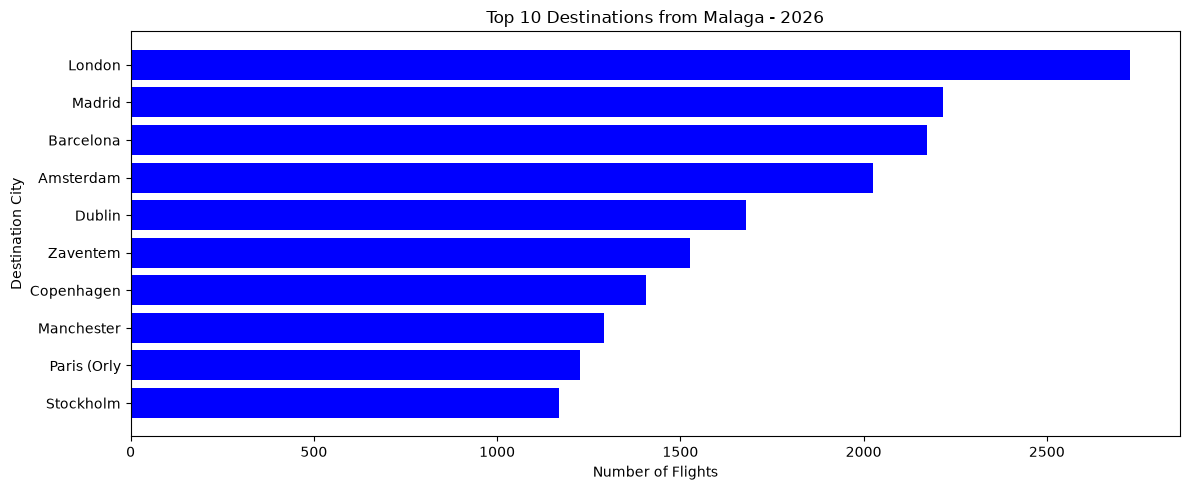

In [26]:
print("===== DATA VISUALIZATION =====")
plt.figure(figsize=(12, 5))

plt.barh(
    top_destinations["municipality"].fillna(top_destinations["ades"]),
    top_destinations["count"],
    color="blue"
)

plt.title("Top 10 Destinations from Malaga - 2026")
plt.xlabel("Number of Flights")
plt.ylabel("Destination City")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Top 10 Origins

This section identifies the most frequent origin airports
for flights arriving in Málaga during January–September 2026.

In [27]:
# ==========================================
# 4. TOP ORIGINS TO MALAGA
# ==========================================

# Filter Malaga arrivals
df_arrivals = df_2026[df_2026["ades"] == "LEMG"].copy()

# Count flights by origin
top_origins = (
    df_arrivals["adep"]
    .value_counts()
    .head(10)
    .reset_index()
)

# Add airport information
top_origins = pd.merge(
    top_origins,
    df_airports[["ident", "name", "municipality", "iso_country"]],
    left_on="adep",
    right_on="ident",
    how="left",
    validate="many_to_one"
)

# Simplify city names
top_origins["municipality"] = (
    top_origins["municipality"]
    .str.split(",")
    .str[0]
    .str.strip()
)

display(top_origins)

,adep,count,ident,name,municipality,iso_country
0,EGKK,2790,EGKK,London Gatwick Airport,London,GB
1,LEMD,2309,LEMD,Adolfo Suárez Madrid–Barajas Airport,Madrid,ES
2,LEBL,2294,LEBL,Josep Tarradellas Barcelona-El Prat Airport,Barcelona,ES
3,EHAM,2141,EHAM,Amsterdam Airport Schiphol,Amsterdam,NL
4,EIDW,1755,EIDW,Dublin Airport,Dublin,IE
5,EBBR,1595,EBBR,Brussels Airport,Zaventem,BE
6,EKCH,1414,EKCH,Copenhagen Kastrup Airport,Copenhagen,DK
7,EGCC,1347,EGCC,Manchester Airport,Manchester,GB
8,LFPO,1256,LFPO,Paris-Orly Airport,Paris (Orly,FR
9,ESSA,1207,ESSA,Stockholm-Arlanda Airport,Stockholm,SE


===== DATA VISUALIZATION =====


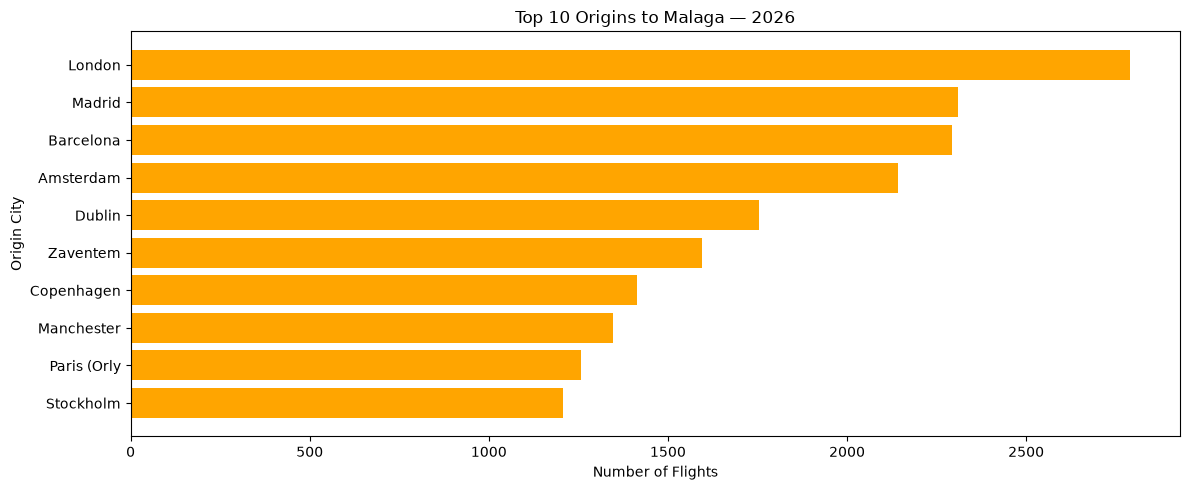

In [28]:
print("===== DATA VISUALIZATION =====")

plt.figure(figsize=(12, 5))

plt.barh(
    top_origins["municipality"].fillna(top_origins["adep"]),
    top_origins["count"],
    color="orange"
)

plt.title("Top 10 Origins to Malaga — 2026")
plt.xlabel("Number of Flights")
plt.ylabel("Origin City")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Flights by Country

This section analyzes the countries with the highest
number of recorded flight connections to and from Málaga.

In [29]:
# ==========================================
# 5. FLIGHTS BY DESTINATION COUNTRY
# ==========================================

# Count departures by airport
departure_counts = (df_departures["ades"].value_counts().reset_index())

# Add countries
departure_counts = pd.merge(
    departure_counts,
    df_airports[["ident", "iso_country"]],
    left_on="ades",
    right_on="ident",
    how="left",
    validate="many_to_one"
)

# Group by destination country
top_destination_countries = (
    departure_counts.groupby("iso_country")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_destination_countries)

iso_country
GB    14352
ES     8893
DE     4242
FR     3985
NL     3181
IT     3001
IE     2479
BE     2333
PL     2031
DK     1950
Name: count, dtype: int64

===== DATA VISUALIZATION =====


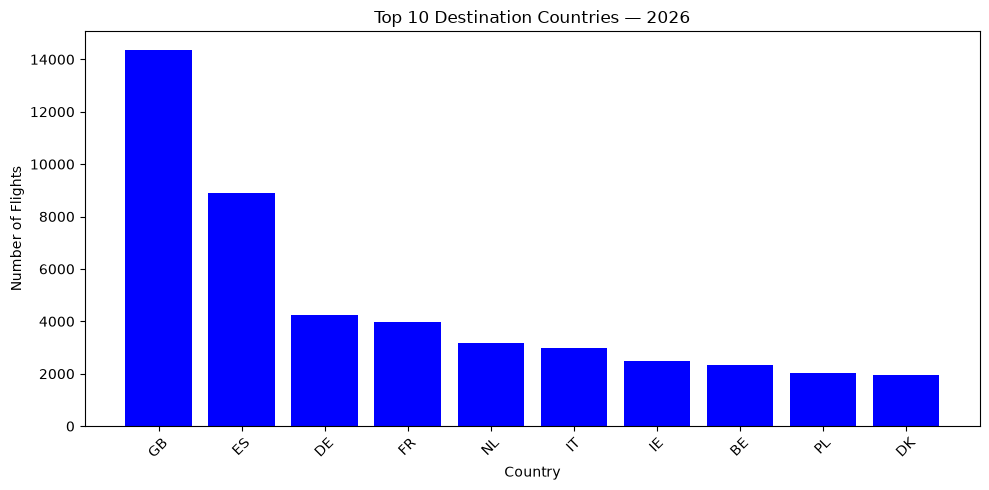

In [30]:
print("===== DATA VISUALIZATION =====")

plt.figure(figsize=(10, 5))

plt.bar(
    top_destination_countries.index,
    top_destination_countries.values,
    color="blue"
)

plt.title("Top 10 Destination Countries — 2026")
plt.xlabel("Country")
plt.ylabel("Number of Flights")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# ==========================================
# 5. FLIGHTS BY ORIGIN COUNTRY
# ==========================================

arrival_counts = (
    df_arrivals["adep"]
    .value_counts()
    .reset_index()
)

arrival_counts = pd.merge(
    arrival_counts,
    df_airports[["ident", "iso_country"]],
    left_on="adep",
    right_on="ident",
    how="left",
    validate="many_to_one"
)

top_origin_countries = (
    arrival_counts.groupby("iso_country")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_origin_countries)

iso_country
GB    15005
ES     9486
DE     4381
FR     4078
NL     3356
IT     3094
IE     2544
BE     2480
PL     2077
DK     1911
Name: count, dtype: int64

===== DATA VISUALIZATION =====


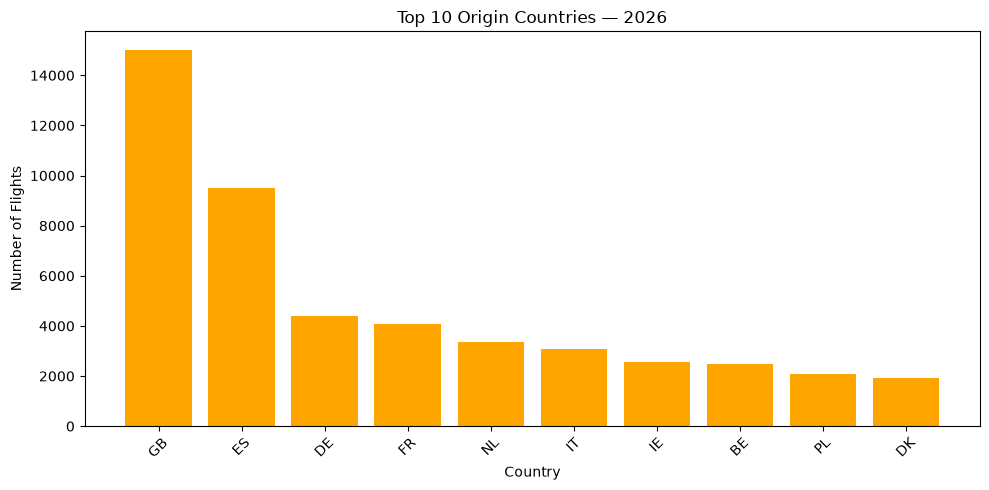

In [32]:
print("===== DATA VISUALIZATION =====")

plt.figure(figsize=(10, 5))

plt.bar(
    top_origin_countries.index,
    top_origin_countries.values,
    color="orange"
)

plt.title("Top 10 Origin Countries — 2026")
plt.xlabel("Country")
plt.ylabel("Number of Flights")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Total Monthly Flights

This section analyzes the total number of recorded flights arriving at or departing from Málaga Airport each month.

The goal is to identify the months with the highest and lowest flight activity and observe possible seasonal trends.

month
1     5803
2    10416
3    14221
4    17331
5    17915
6    19329
7    22065
8    20163
9    19395
Name: count, dtype: int64

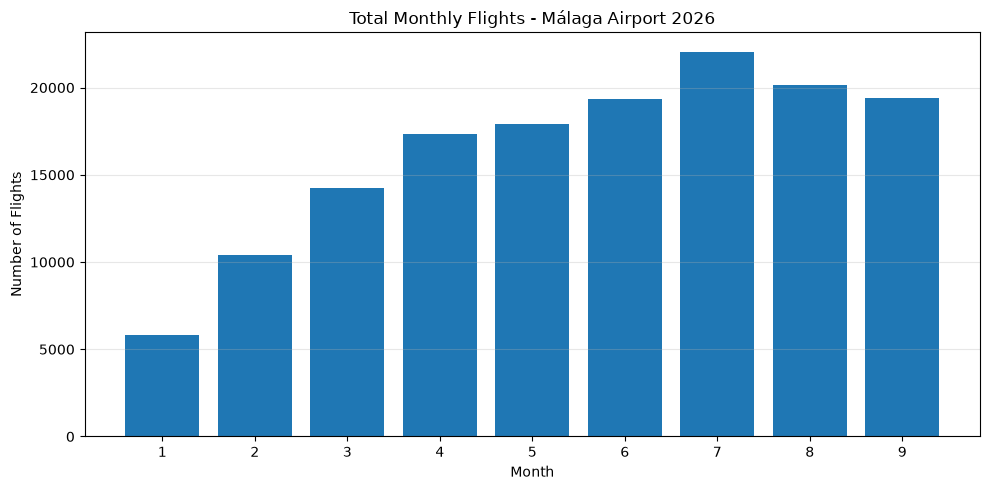

Total recorded flights: 146638
Month with most flights: 7
Maximum monthly flights: 22065
Month with fewest flights: 1
Minimum monthly flights: 5803


In [33]:
# ==========================================
# 6. TOTAL MONTHLY FLIGHTS
# ==========================================

# Count total flights per month
# Count total flights per month using the already prepared month column
monthly_flights = (
    df_2026["month"]
    .value_counts()
    .sort_index()
    .reindex(range(1, 10), fill_value=0)
)

# Display monthly flight counts
display(monthly_flights)

# Data visualization
plt.figure(figsize=(10, 5))

plt.bar(monthly_flights.index, monthly_flights.values)

plt.title("Total Monthly Flights - Málaga Airport 2026")
plt.xlabel("Month")
plt.ylabel("Number of Flights")

plt.xticks(range(1, 10))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Summary
print("Total recorded flights:", monthly_flights.sum())
print("Month with most flights:", monthly_flights.idxmax())
print("Maximum monthly flights:", monthly_flights.max())
print("Month with fewest flights:", monthly_flights.idxmin())
print("Minimum monthly flights:", monthly_flights.min())


In [34]:
import calendar

print("Month with most flights:",
      calendar.month_name[monthly_flights.idxmax()])

print("Month with fewest flights:",
      calendar.month_name[monthly_flights.idxmin()])

Month with most flights: July
Month with fewest flights: January


## Final Conclusions

This project analyzed recorded flights arriving at and departing from Málaga-Costa del Sol Airport between January and September 2026.

### Main Findings

**Flight Activity**

- A total of **146,638** Málaga-related flight records were identified between January and September 2026.
- **July** recorded the highest flight activity, with **22,065** flights.
- **January** recorded the lowest flight activity, with **5,803** flights.
- Flight activity generally increased from January to July, followed by a slight decrease in August and September.
- This trend suggests possible seasonal variations, with higher recorded flight activity during the summer months.

**Most Frequent Destinations**

- The most frequent destination airport was **London Gatwick Airport**, with **2727** recorded flights.
- Other important destinations included **Adolfo Suárez Madrid–Barajas Airport** and **Josep Tarradellas Barcelona-El Prat Airport**.

**Most Frequent Origins**

- The most frequent origin airport was **London Gatwick Airport**, with **2790** recorded flights.
- Other frequent origins included **Adolfo Suárez Madrid–Barajas Airport** and **Josep Tarradellas Barcelona-El Prat Airport**.

**Countries**

- **The United Kingdom** had the highest number of recorded flight connections with Málaga.
- Other significant countries included **Spain** and **Denmark**.


### Data Limitations

The analysis is based on flight records available in the source dataset and may not represent all airport operations.

Some airport information may be missing, and the results describe flight counts rather than passenger numbers.